# 03 · Décision, seuil et ROI

**Objectif** (axes 6, 7 et 9) : traduire les erreurs du modèle en euros, choisir le seuil de décision par le coût, estimer le ROI et ses limites.

On repart des probabilités produites par le notebook 02 :
- `train_oof.csv` : probabilités hors échantillon sur l'entraînement, utilisées pour **choisir** le seuil ;
- `test.csv` : probabilités sur le test (été 2008), utilisées **une seule fois** pour mesurer le résultat final.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from modeling import HYPOTHESES, best_threshold, campaign_cost, threshold_table

FIG = ROOT / "reports" / "figures"
PRED = ROOT / "reports" / "predictions"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

oof = pd.read_csv(PRED / "train_oof.csv")
test = pd.read_csv(PRED / "test.csv")
print(f"Entraînement : {len(oof):,} joueurs · Test : {len(test):,} joueurs")

Entraînement : 8,265 joueurs · Test : 6,918 joueurs


## 1. Matrice de coûts (hypothèses explicites)

Situation : à chaque coupure (une par trimestre), l'équipe rétention envoie une offre « **un mois d'abonnement offert** » aux joueurs que le modèle signale.

| Hypothèse | Valeur | Justification |
| --- | --- | --- |
| Prix de l'abonnement | 12,99 €/mois | Prix public européen de WoW, inchangé depuis le lancement ([RTBF](https://www.rtbf.be/article/world-of-warcraft-pourquoi-le-prix-de-l-abonement-ne-devrait-jamais-augmente-11504182)) |
| Valeur d'un joueur retenu | 12 mois × 12,99 € = 155,88 € | Hypothèse : un joueur retenu reste en moyenne un an de plus |
| Coût d'une offre | 12,99 € | Un mois offert = un mois de revenu en moins, que le joueur parte ou non |
| Taux de réussite de l'offre | 25 % | Hypothèse : une offre retient 1 joueur sur 4 parmi ceux qui allaient partir. **À valider par un test A/B** |

Conséquence pour chaque cas :

| Cas | Ce qui se passe | Coût |
| --- | --- | --- |
| **FN** : départ non repéré | Le joueur part | 155,88 € de revenu perdu |
| **TP** : départ repéré | Offre envoyée ; 25 % restent, 75 % partent quand même | 12,99 + 0,75 × 155,88 = 129,90 € |
| **FP** : fidèle signalé à tort | Offre envoyée pour rien | 12,99 € |
| **TN** : fidèle non signalé | Rien | 0 € |

Repérer un départ fait donc économiser 155,88 − 129,90 = **25,98 €**, et une fausse alerte coûte **12,99 €**. Une offre est rentable dès que la probabilité de départ dépasse environ 12,99 / (0,25 × 155,88) ≈ **0,33**, si les probabilités du modèle étaient parfaitement calibrées.

In [2]:
valeur = HYPOTHESES["abonnement_mois"] * HYPOTHESES["mois_gagnes"]
print("Hypothèses :", HYPOTHESES)
print(f"Valeur d'un joueur retenu : {valeur:.2f} €")
print(f"Coût FN = {valeur:.2f} € · coût TP = {HYPOTHESES['cout_offre'] + (1 - HYPOTHESES['taux_reussite']) * valeur:.2f} € · "
      f"coût FP = {HYPOTHESES['cout_offre']:.2f} €")

Hypothèses : {'abonnement_mois': 12.99, 'mois_gagnes': 12, 'cout_offre': 12.99, 'taux_reussite': 0.25}
Valeur d'un joueur retenu : 155.88 €
Coût FN = 155.88 € · coût TP = 129.90 € · coût FP = 12.99 €


## 2. Choix du seuil sur l'entraînement (probabilités hors échantillon)

,seuil,TP,FP,FN,offres,precision,recall,F1,cout
0,0.20,2400,2019,197,4419,0.543,0.924,0.684,368695.17
1,0.30,2202,1444,395,3646,0.604,0.848,0.705,366369.96
2,0.37,2044,1090,553,3134,0.652,0.787,0.713,365876.34
3,0.50,1614,562,983,2176,0.742,0.621,0.676,370189.02
4,0.70,1078,197,1519,1275,0.845,0.415,0.557,379372.95


Seuil qui minimise le coût sur l'entraînement : 0.37


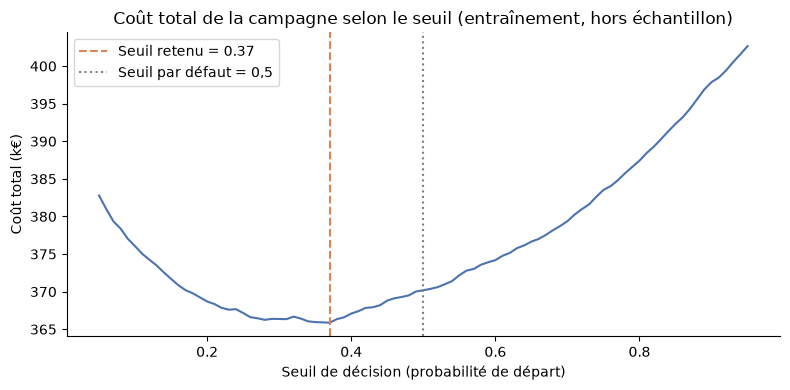

In [3]:
seuil_opt, courbe = best_threshold(oof["y"], oof["proba"])
comparaison_seuils = threshold_table(oof["y"], oof["proba"], [0.2, 0.3, seuil_opt, 0.5, 0.7])
comparaison_seuils["F1"] = 2 * comparaison_seuils["precision"] * comparaison_seuils["recall"] / (
    comparaison_seuils["precision"] + comparaison_seuils["recall"])
display(comparaison_seuils[["seuil", "TP", "FP", "FN", "offres", "precision", "recall", "F1", "cout"]].round(3))
print(f"Seuil qui minimise le coût sur l'entraînement : {seuil_opt:.2f}")

fig, ax = plt.subplots()
ax.plot(courbe["seuil"], courbe["cout"] / 1000, color="#4C72B0")
ax.axvline(seuil_opt, color="#DD8452", ls="--", label=f"Seuil retenu = {seuil_opt:.2f}")
ax.axvline(0.5, color="grey", ls=":", label="Seuil par défaut = 0,5")
ax.set_title("Coût total de la campagne selon le seuil (entraînement, hors échantillon)")
ax.set_xlabel("Seuil de décision (probabilité de départ)")
ax.set_ylabel("Coût total (k€)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "09_cout_selon_seuil.png", dpi=150)
plt.show()

**Lecture** : le seuil de 0,5 n'est pas le meilleur. Un seuil plus bas fait repérer davantage de départs au prix de quelques offres inutiles de plus, ce qui est rentable car une fausse alerte (12,99 €) coûte moins que ce que rapporte un départ repéré (25,98 €). Le seuil retenu (0,37) est choisi **sur l'entraînement**, sans regarder le test. Il est proche du seuil théorique de 0,33 calculé plus haut.

Le seuil 0,37 n'a pas le meilleur F1 du tableau par hasard : ici F1 et coût vont dans le même sens. En revanche, le seuil 0,7 aurait la meilleure Precision (85 %) mais coûterait environ 13 500 € de plus par campagne, car il laisse partir beaucoup de joueurs. La courbe est assez plate entre 0,3 et 0,45 : le choix exact du seuil n'est pas fragile.

## 3. Résultat final sur le test (été 2008)

Seuil appliqué : 0.37
Recall    : 81.7%  (critère de succès : ≥ 70 %)
Precision : 56.5%  (critère de succès : ≥ 33 %)
Offres envoyées : 2,616 sur 6,918 joueurs actifs
Sur 100 joueurs qui partent, le modèle en repère 82.
Sur 100 offres envoyées, 56 vont à des joueurs réellement sur le départ.


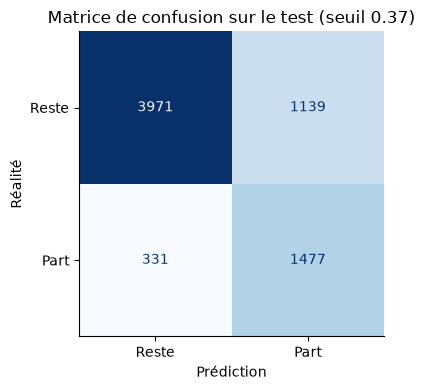

In [4]:
pred_test = (test["proba"] >= seuil_opt).astype(int)
res = campaign_cost(test["y"], pred_test)
print(f"Seuil appliqué : {seuil_opt:.2f}")
print(f"Recall    : {res['recall']:.1%}  (critère de succès : ≥ 70 %)")
print(f"Precision : {res['precision']:.1%}  (critère de succès : ≥ 33 %)")
print(f"Offres envoyées : {res['offres']:,} sur {len(test):,} joueurs actifs")
print(f"Sur 100 joueurs qui partent, le modèle en repère {100 * res['recall']:.0f}.")
print(f"Sur 100 offres envoyées, {100 * res['precision']:.0f} vont à des joueurs réellement sur le départ.")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(test["y"], pred_test, ax=ax, cmap="Blues",
                                        display_labels=["Reste", "Part"], colorbar=False)
ax.set_title(f"Matrice de confusion sur le test (seuil {seuil_opt:.2f})")
ax.set_xlabel("Prédiction")
ax.set_ylabel("Réalité")
plt.tight_layout()
plt.savefig(FIG / "10_confusion_test_seuil.png", dpi=150)
plt.show()

**Lecture** : sur une période jamais vue, le modèle dépasse les deux critères de succès fixés dans la note de cadrage (Recall ≥ 70 %, Precision ≥ 33 %).

## 4. Comparaison des stratégies sur le test

,offres,TP,FP,FN,precision,recall,cout,écart vs règle actuelle (€)
Aucune campagne,0.0,0.0,0.0,1808.0,0.000,0.000,281831.0,10483.0
Offre à tous,6918.0,1808.0,5110.0,0.0,0.261,1.000,301238.0,29890.0
Règle actuelle (absent > 14 j),1788.0,865.0,923.0,943.0,0.484,0.478,271348.0,0.0
"Modèle, seuil 0,5",1747.0,1173.0,574.0,635.0,0.671,0.649,258813.0,-12535.0
"Modèle, seuil 0.37",2616.0,1477.0,1139.0,331.0,0.565,0.817,258254.0,-13094.0


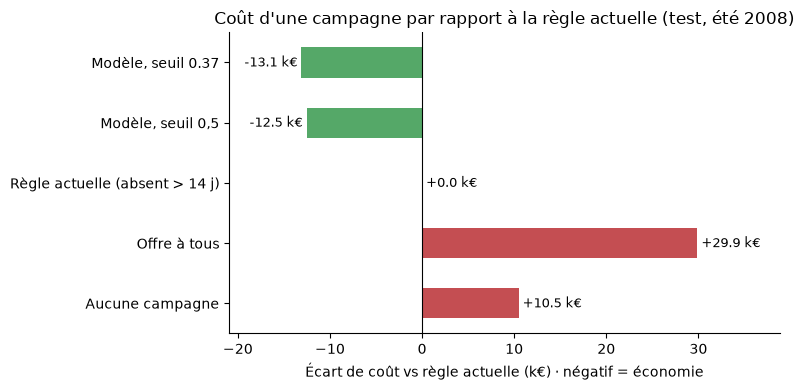

In [5]:
strategies = {
    "Aucune campagne": np.zeros(len(test), dtype=int),
    "Offre à tous": np.ones(len(test), dtype=int),
    "Règle actuelle (absent > 14 j)": test["regle_14j"].to_numpy(),
    "Modèle, seuil 0,5": (test["proba"] >= 0.5).astype(int),
    f"Modèle, seuil {seuil_opt:.2f}": pred_test,
}
bilan = pd.DataFrame({nom: campaign_cost(test["y"], p) for nom, p in strategies.items()}).T
bilan = bilan[["offres", "TP", "FP", "FN", "precision", "recall", "cout"]].astype(float)
bilan["écart vs règle actuelle (€)"] = bilan["cout"] - bilan.loc["Règle actuelle (absent > 14 j)", "cout"]
display(bilan.round({"precision": 3, "recall": 3, "cout": 0, "écart vs règle actuelle (€)": 0}))

ecart = bilan["écart vs règle actuelle (€)"] / 1000
fig, ax = plt.subplots(figsize=(8, 4))
couleurs = ["#55A868" if v < 0 else "#C44E52" for v in ecart]
ecart.plot(kind="barh", ax=ax, color=couleurs)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Coût d'une campagne par rapport à la règle actuelle (test, été 2008)")
ax.set_xlabel("Écart de coût vs règle actuelle (k€) · négatif = économie")
for i, v in enumerate(ecart):
    ax.text(v, i, f" {v:+.1f} k€ ", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlim(ecart.min() * 1.6, ecart.max() * 1.3)
plt.tight_layout()
plt.savefig(FIG / "11_strategies.png", dpi=150)
plt.show()

**Lecture** :
- « Offre à tous » est la pire stratégie : elle paie des milliers d'offres à des joueurs fidèles.
- La règle actuelle fait un peu mieux que ne rien faire, mais elle rate plus de la moitié des départs.
- Le modèle au seuil retenu est la stratégie la moins coûteuse : environ 13 100 € de moins par campagne que la règle actuelle. Il envoie plus d'offres (2 616 contre 1 788), mais elles sont mieux ciblées (56 % utiles contre 48 %) et il repère 1 477 départs au lieu de 865.
- Sur le test, les seuils 0,37 et 0,5 ont des coûts proches (environ 560 € d'écart) : l'essentiel du gain vient du modèle lui-même. Le seuil 0,37 permet de repérer 82 % des départs au lieu de 65 %, pour un coût équivalent, ce qui laisse plus de joueurs à qui parler.

Attention : le coût total inclut les revenus perdus des joueurs qui partent, qu'on ne peut jamais éviter entièrement. Ce qui compte pour la décision, c'est l'**écart** entre stratégies.

## 5. ROI (axe 7)

Hypothèses supplémentaires :
- **Périmètre** : un serveur d'environ 7 000 joueurs actifs, comme dans les données. Une campagne par trimestre, soit 4 par an, chacune supposée comparable au test.
- **Référence** : la règle actuelle (relance après 14 jours d'absence).
- **Coût du projet la 1re année** : 25 000 € de développement (environ 2 mois d'un data scientist) + 10 000 € d'exploitation (calcul trimestriel, suivi, réentraînement) = **35 000 €**.

In [6]:
COUT_PROJET = 25_000 + 10_000
CAMPAGNES_PAR_AN = 4
cout_regle = bilan.loc["Règle actuelle (absent > 14 j)", "cout"]
cout_modele = bilan.loc[f"Modèle, seuil {seuil_opt:.2f}", "cout"]

gain_campagne = cout_regle - cout_modele
gain_annuel = CAMPAGNES_PAR_AN * gain_campagne
roi = (gain_annuel - COUT_PROJET) / COUT_PROJET * 100
retour_mois = COUT_PROJET / (gain_annuel / 12)

print(f"Coût par campagne : règle actuelle {cout_regle:,.0f} € · modèle {cout_modele:,.0f} €")
print(f"Gain par campagne : {gain_campagne:,.0f} €")
print(f"Gain annuel ({CAMPAGNES_PAR_AN} campagnes) : {gain_annuel:,.0f} €")
print(f"Coût du projet (1re année) : {COUT_PROJET:,.0f} €")
print(f"ROI 1re année : {roi:.0f} %")
print(f"Délai de retour : {retour_mois:.1f} mois")

Coût par campagne : règle actuelle 271,348 € · modèle 258,254 €
Gain par campagne : 13,094 €
Gain annuel (4 campagnes) : 52,376 €
Coût du projet (1re année) : 35,000 €
ROI 1re année : 50 %
Délai de retour : 8.0 mois


## 6. Analyse de sensibilité

In [7]:
scenarios = {
    "Central": {},
    "Pessimiste : offre efficace à 15 %": {"taux_reussite": 0.15},
    "Pessimiste : joueur retenu 6 mois": {"mois_gagnes": 6},
    "Optimiste : offre efficace à 35 %": {"taux_reussite": 0.35},
    "Bonus en jeu à 3 €, efficace à 10 %": {"cout_offre": 3.0, "taux_reussite": 0.10},
}
lignes = []
for nom, changements in scenarios.items():
    h = {**HYPOTHESES, **changements}
    s, _ = best_threshold(oof["y"], oof["proba"], h)  # seuil ré-optimisé sur l'entraînement
    c_mod = campaign_cost(test["y"], (test["proba"] >= s).astype(int), h)["cout"]
    c_reg = campaign_cost(test["y"], test["regle_14j"], h)["cout"]
    g = CAMPAGNES_PAR_AN * (c_reg - c_mod)
    lignes.append({"Scénario": nom, "Seuil": s, "Gain annuel vs règle (€)": round(g),
                   "ROI 1re année (%)": round((g - COUT_PROJET) / COUT_PROJET * 100),
                   "Retour (mois)": round(COUT_PROJET / (g / 12), 1) if g > 0 else np.nan})
sensibilite = pd.DataFrame(lignes).set_index("Scénario")
display(sensibilite)

,Seuil,Gain annuel vs règle (€),ROI 1re année (%),Retour (mois)
Scénario,,,,
Central,0.37,52376,50,8.0
Pessimiste : offre efficace à 15 %,0.54,33753,-4,12.4
Pessimiste : joueur retenu 6 mois,0.67,36112,3,11.6
Optimiste : offre efficace à 35 %,0.22,86337,147,4.9
"Bonus en jeu à 3 €, efficace à 10 %",0.17,28614,-18,14.7


**Lecture** :
- Scénario central : environ 52 000 € de gain par an, ROI de 50 % la 1re année, remboursé en 8 mois.
- Scénarios pessimistes (offre efficace à 15 % seulement, ou joueur retenu 6 mois au lieu de 12) : le projet est **tout juste à l'équilibre la 1re année** (ROI entre −4 % et +3 %, retour en environ un an). Il devient rentable dès la 2e année, puisque le développement n'est payé qu'une fois.
- Le ROI dépend donc surtout du **taux de réussite de l'offre**, l'hypothèse la plus incertaine : c'est elle qu'il faut mesurer en priorité, avec un test A/B (offre envoyée à une partie seulement des joueurs signalés).
- Le seuil s'adapte aux hypothèses : quand l'offre est moins efficace, il faut être plus sélectif (seuil plus haut) ; quand l'offre coûte moins cher, on peut cibler plus large.
- Un bonus en jeu à 3 € coûte moins cher, mais il retient sans doute beaucoup moins qu'un mois offert : sans abonnement, on ne peut pas jouer. Avec une efficacité de 10 %, le ROI de la 1re année devient négatif (−18 %). L'offre la moins chère n'est donc pas forcément la meilleure.
- Le calcul porte sur **un seul serveur**. Un éditeur de MMO en exploite des dizaines ou des centaines : le coût du projet serait partagé et le gain multiplié, à condition que le modèle se généralise aux autres serveurs (à vérifier).

## 7. Registre des risques (axe 9)

| Risque | Catégorie | Probabilité | Impact | Mesure de réduction |
| --- | --- | --- | --- | --- |
| Taux de réussite réel de l'offre plus faible que 25 % | Métier | Moyenne | Élevé | Test A/B sur une campagne pilote avant généralisation |
| Dérive : comportement des joueurs différent après une extension ou une mise à jour majeure | Technique | Élevée | Élevé | Suivi trimestriel du PR-AUC et du Recall ; réentraînement à chaque coupure |
| Un personnage n'est pas un joueur : plusieurs personnages par compte faussent la cible | Technique | Élevée | Moyen | En production, travailler au niveau du compte (identifiant d'abonnement), absent de ces données |
| Joueurs qui « attendent » l'offre (effet d'aubaine) | Métier | Moyenne | Moyen | Limiter à une offre par joueur et par an ; varier les offres |
| Données d'un seul serveur et d'une seule faction | Technique | Certaine | Moyen | Valider le modèle sur d'autres serveurs avant tout déploiement |
| Données personnelles (historique de connexion) | Éthique / RGPD | Faible | Élevé | Identifiants anonymisés, finalité limitée à la rétention, information des joueurs dans les CGU |
| Ciblage perçu comme injuste (offre réservée aux joueurs « à risque ») | Éthique | Faible | Moyen | Race et classe n'ont presque aucun poids ; règle de ciblage documentée et explicable |
| Coût énergétique | Environnemental | Faible | Faible | Modèle léger (≈ 1 minute d'entraînement sur un ordinateur portable), 4 calculs par an |

## 8. Recommandation

Remplacer la règle « relancer après 14 jours d'absence » par un ciblage trimestriel fondé sur le modèle, au seuil choisi par le coût. Avant de généraliser, lancer **un pilote d'une campagne** avec un groupe témoin, pour mesurer le vrai taux de réussite de l'offre, l'hypothèse dont dépend le plus le ROI.

In [8]:
# Résumé
print("=== Résumé ===")
print(f"Seuil retenu : {seuil_opt:.2f}")
print(f"Test (été 2008) : Recall {res['recall']:.1%}, Precision {res['precision']:.1%}, {res['offres']:,} offres")
print(f"Gain annuel vs règle actuelle : {gain_annuel:,.0f} € · ROI 1re année : {roi:.0f} % · retour en {retour_mois:.1f} mois")

=== Résumé ===
Seuil retenu : 0.37
Test (été 2008) : Recall 81.7%, Precision 56.5%, 2,616 offres
Gain annuel vs règle actuelle : 52,376 € · ROI 1re année : 50 % · retour en 8.0 mois
